<a href="https://colab.research.google.com/github/roysam0963/COU07506-labs/blob/main/COU07506_Week02_240242494755.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 — Digital Signal Processing
## WEEK 2: Sampling, Aliasing and Quantization

**Name:** SADIKI MARKO MSUKWA
**Registration Number:** 240242494755
**Class:** BEng24COE3
**Date:** 23 November 2026

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
import os

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 2 DSP Laboratory is ready!")

## Pre-lab Preparation

**Question (a): A 7 kHz tone is sampled at 10 kHz. What frequency appears?**

**Answer:**

The Nyquist frequency is:

fN = fs / 2 = 10 / 2 = 5 kHz

Since the input frequency (7 kHz) is greater than the Nyquist frequency, aliasing occurs.

The alias frequency is:

f_alias = |7 - 10| = 3 kHz

Therefore, the frequency that appears is **3 kHz**.

**Question (b): Compute Δ and the theoretical SQNR for an 8-bit quantizer with a ±1 V range.**

**Answer:**

Given:

- Number of bits (B) = 8
- Full-scale range = ±1 V
- Xm = 1 V

Quantization step size:

Δ = 2Xm / 2^B

Δ = 2(1) / 2^8

Δ = 2 / 256 = **0.0078125 V**

Theoretical SQNR:

SQNR = 6.02B + 1.76

SQNR = 6.02(8) + 1.76

SQNR = **49.92 dB**

## Task 2.1: Demonstrating Aliasing

The aim of this task is to demonstrate aliasing when a signal is sampled below the Nyquist rate.

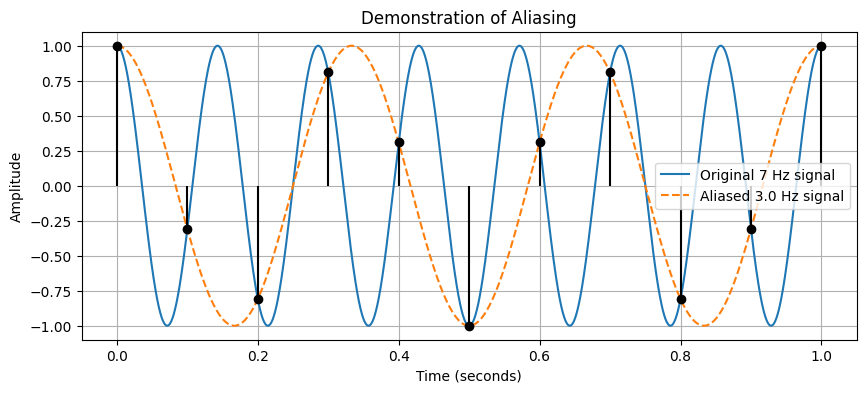

Original frequency: 7.0 Hz
Sampling frequency: 10.0 Hz
Alias frequency: 3.0 Hz


In [3]:
f0 = 7.0
fs = 10.0

t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs

f_alias = abs(f0 - fs * round(f0 / fs))

plt.figure(figsize=(10, 4))

plt.plot(t, np.cos(2*np.pi*f0*t),
         label="Original 7 Hz signal")

plt.plot(t, np.cos(2*np.pi*f_alias*t), "--",
         label=f"Aliased {f_alias} Hz signal")

plt.stem(tn, np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Demonstration of Aliasing")
plt.legend()
plt.grid(True)
plt.show()

print("Original frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Alias frequency:", f_alias, "Hz")

In [4]:
f0 = 7.0

sampling_rates = [10, 12, 14, 20]

print("Sampling Frequency | Alias Frequency")
print("-------------------------------------")

for fs in sampling_rates:
    f_alias = abs(f0 - fs * round(f0 / fs))
    print(f"{fs:18} | {f_alias} Hz")

Sampling Frequency | Alias Frequency
-------------------------------------
                10 | 3.0 Hz
                12 | 5.0 Hz
                14 | 7.0 Hz
                20 | 7.0 Hz


**Observation:**

When the sampling frequency is low, aliasing occurs and the observed frequency differs from the original frequency.

At a sampling frequency of 10 Hz, the original 7 Hz signal appears as a 3 Hz signal.

Increasing the sampling frequency reduces aliasing. At 20 Hz, the original 7 Hz frequency is correctly represented.

In [5]:
import os

if os.path.exists("/content/my_voice.wav"):
    print("Voice recording is available!")
else:
    print("Voice recording not found. Please upload it.")

Voice recording not found. Please upload it.


In [6]:
from google.colab import files

uploaded = files.upload()

Saving my_voice.wav.mp4 to my_voice.wav.mp4


In [9]:
fs, x = wavfile.read("/content/my_voice.wav")

if x.ndim > 1:
    x = x.mean(axis=1)

x = x.astype(float)

peak = np.max(np.abs(x))
if peak > 0:
    x = x / peak

print("Original Sampling Rate:", fs, "Hz")
print("Number of Samples:", len(x))
print("Duration:", round(len(x) / fs, 2), "seconds")

Original Sampling Rate: 16000 Hz
Number of Samples: 77824
Duration: 4.86 seconds


In [12]:
for k in [2, 4, 8]:

    naive = x[::k]

    proper = signal.decimate(x, k, ftype="fir")

    new_fs = fs // k

    print("\nk =", k)
    print("New Sampling Rate:", new_fs, "Hz")

    print("Naive version:")
    display(Audio(naive, rate=new_fs))

    print("Filtered version:")
    display(Audio(proper, rate=new_fs))


k = 2
New Sampling Rate: 8000 Hz
Naive version:


Filtered version:



k = 4
New Sampling Rate: 4000 Hz
Naive version:


Filtered version:



k = 8
New Sampling Rate: 2000 Hz
Naive version:


Filtered version:


**Observation:**

The naive version produced a noticeable change in audio quality because samples were removed without applying an anti-aliasing filter.

The filtered version maintained better audio quality because a low-pass filter was applied before downsampling.

At k = 8, the difference became more noticeable because the sampling rate was reduced significantly.

## Task 2.3: Uniform Quantization

The aim of this task is to implement a uniform quantizer and observe quantization error.

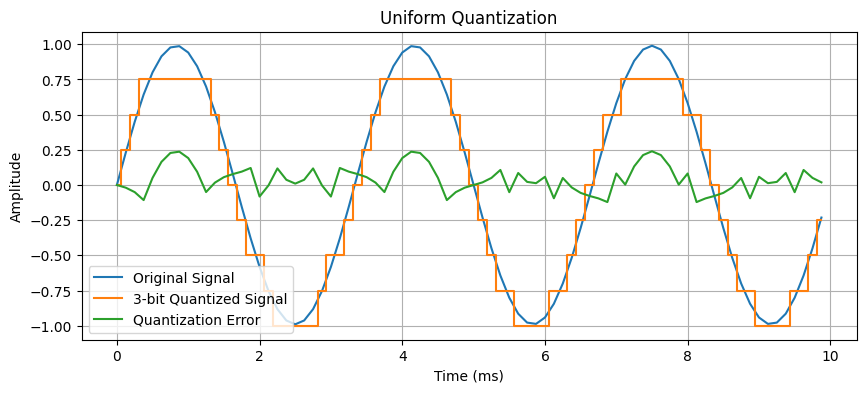

In [13]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)


fs = 8000
t = np.arange(0, 0.01, 1/fs)

x_sine = 0.99 * np.sin(2 * np.pi * 300 * t)

xq = quantize(x_sine, 3)

plt.figure(figsize=(10, 4))

plt.plot(t*1e3, x_sine, label="Original Signal")
plt.step(t*1e3, xq, where="mid", label="3-bit Quantized Signal")
plt.plot(t*1e3, x_sine - xq, label="Quantization Error")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Uniform Quantization")
plt.legend()
plt.grid(True)
plt.show()

## Task 2.4: Measuring SQNR

The aim of this task is to measure the Signal-to-Quantization-Noise Ratio (SQNR) for different quantization bit depths and compare the results with the theoretical formula.

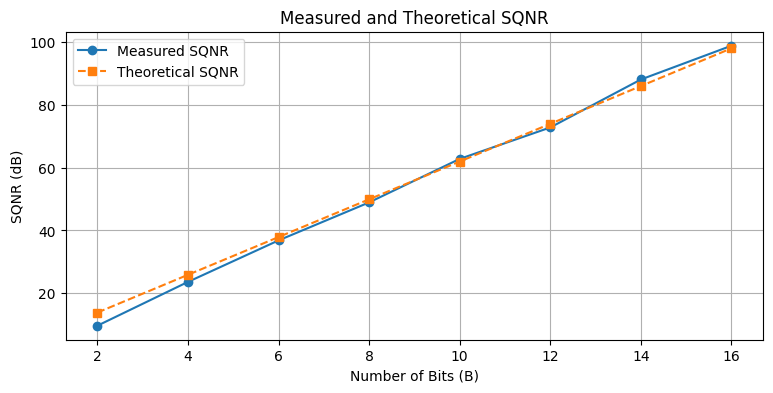

Bits: [ 2  4  6  8 10 12 14 16]
Measured SQNR: [ 9.6  23.58 36.81 48.93 62.81 72.84 88.13 98.91]
Theoretical SQNR: [13.8  25.84 37.88 49.92 61.96 74.   86.04 98.08]


In [14]:
bits = np.arange(2, 17, 2)

meas = [
    10 * np.log10(
        np.sum(x_sine**2) /
        np.sum((x_sine - quantize(x_sine, B))**2)
    )
    for B in bits
]

plt.figure(figsize=(9, 4))

plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, 6.02*bits + 1.76, "s--",
         label="Theoretical SQNR")

plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Measured and Theoretical SQNR")
plt.legend()
plt.grid(True)
plt.show()

print("Bits:", bits)
print("Measured SQNR:", np.round(meas, 2))
print("Theoretical SQNR:", np.round(6.02*bits + 1.76, 2))

**Observation:**

The graph shows that SQNR increases as the number of quantization bits increases.

Each additional bit improves the theoretical SQNR by approximately 6.02 dB. The measured SQNR generally follows the theoretical trend.

## Task 2.5: Quantization of Voice Recording

The aim of this task is to quantize a voice recording using 4-bit, 8-bit and 12-bit quantizers, listen to the results and calculate SQNR.

In [16]:
bits_list = [4, 8, 12]

for B in bits_list:

    x_quantized = quantize(x, B)

    error = x - x_quantized

    sqnr = 10 * np.log10(
        np.sum(x**2) / np.sum(error**2)
    )

    print(f"\nQuantization: {B}-bit")
    print(f"SQNR: {sqnr:.2f} dB")

    display(Audio(x_quantized, rate=fs))


Quantization: 4-bit
SQNR: 11.29 dB



Quantization: 8-bit
SQNR: 35.25 dB



Quantization: 12-bit
SQNR: 59.33 dB


## Analysis Questions

### 1. Explain with a frequency-axis sketch why a 7 Hz tone appears at 3 Hz when fs = 10 Hz.

The Nyquist frequency is:

fN = fs / 2 = 10 / 2 = 5 Hz

Since the original frequency (7 Hz) is greater than the Nyquist frequency (5 Hz), aliasing occurs.

The alias frequency is:

f_alias = |7 - 10| = 3 Hz

Therefore, the 7 Hz signal appears as a 3 Hz signal after sampling.

### 2. In Task 2.2, why can aliasing heard in the naive version not be removed afterwards?

Aliasing cannot easily be removed after sampling because different original frequencies may produce the same sampled frequency.

Once the frequencies overlap, the original signal information is lost.

An anti-aliasing low-pass filter should therefore be applied before downsampling.

### 3. By how much does SQNR change when one bit is added? Does measurement agree?

The theoretical SQNR increases by approximately 6.02 dB for every additional bit.

The measured results generally follow this theoretical relationship, although small differences may occur due to the signal and quantization process.

### 4. A temperature sensor changes by at most 0.1 °C/s and requires resolution of 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits and justify.

The sensor changes at a maximum rate of 0.1 °C/s.

A sampling rate of 1 sample per second is sufficient to monitor the temperature change.

For the quantizer, the required resolution is 0.01 °C over a 100 °C range.

Number of levels required:

100 / 0.01 = 10,000 levels

Number of bits:

B = ceil(log2(10,000))

B = 14 bits

Therefore, a sampling rate of 1 Hz and a 14-bit quantizer are suitable.